# Question 3.(g) -- battery model checks

Runs the battery model of `src/model.py` and checks it against the formulation of 3.(g).i in the
report: the value $\pi^{\mathrm{end}}$, every constraint, the objective, the overlap argument of
(ii), and the comparison with the model without battery (3.(d)). Every check prints `OK` or
`FAIL`; the last cell runs `main.py` for each case, as from the terminal.

Run with **Kernel -> Restart & Run All**.

In [21]:
import subprocess
import sys
from pathlib import Path

ROOT_DIR = Path.cwd()
while not (ROOT_DIR / "src").exists() and ROOT_DIR != ROOT_DIR.parent:
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data_loader import load_question
from src.model import FlexibleConsumerModel, terminal_value
from src.plotting import plot_battery_schedule

TOL = 1e-6


def check(name, error, tol=TOL):
    # Print OK/FAIL for one check; error is the largest violation found
    print(f"{'OK  ' if error <= tol else 'FAIL'}  {name:55s} {error:.2e}")
    return error <= tol

## 1. Input data

In [22]:
d = load_question("Q3_battery")
print(d.summary())

Case                 : Q3_battery
Consumer             : C_03_BAT
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : None
Min daily energy     : 40.0
Reference profile    : yes (32.3 kWh/day)
Disutility lin/quad  : None / 1.0
Battery              : 4.0 kWh, 1.5/1.5 kW, eta 0.95/0.95, initial SoC 2.0 kWh
Next-day forecasts   : yes


## 2. $\pi^{\mathrm{end}}$ step by step

The same formula as eq. (g_piend) of the report, computed here by hand and compared with
`terminal_value(d)` in the code. Nothing is hard-coded: everything comes from the next-day data.

In [23]:
p_next = d.energy_price_next_day                       # p_{D+1,t}
p_imp_next = p_next + d.import_tariff                  # p^imp_{D+1,t}
t_peak = int(np.argmax(p_next[:12]))                   # morning price peak of the following day
night = list(range(t_peak))                            # T^night_{D+1}
replace_cost = min(p_imp_next[t] for t in night) / d.battery_charging_efficiency
use_value = d.battery_discharging_efficiency * p_imp_next.max()
pi_end = min(replace_cost, use_value)

print(f"t_peak = {t_peak}, night hours = {night}")
print(f"cheapest night hour = {night[int(np.argmin(p_imp_next[night]))]}, "
      f"p_imp = {p_imp_next[night].min():.2f} DKK/kWh")
print(f"replacement cost = {replace_cost:.4f}   use value (cap) = {use_value:.4f}   pi_end = {pi_end:.4f} DKK/kWh")
print(f"refill assumption |night| * eta_ch * P_ch = "
      f"{len(night) * d.battery_charging_efficiency * d.battery_max_charge_kW:.2f} >= E_bat = {d.battery_capacity_kWh}")
check("pi_end by hand = terminal_value(d)", abs(pi_end - terminal_value(d)))

t_peak = 9, night hours = [0, 1, 2, 3, 4, 5, 6, 7, 8]
cheapest night hour = 4, p_imp = 1.35 DKK/kWh
replacement cost = 1.4211   use value (cap) = 2.7550   pi_end = 1.4211 DKK/kWh
refill assumption |night| * eta_ch * P_ch = 12.82 >= E_bat = 4.0
OK    pi_end by hand = terminal_value(d)                      0.00e+00


np.True_

## 3. Solve the models with and without battery

In [24]:
res_bat = FlexibleConsumerModel(d).build().solve()
res_nobat = FlexibleConsumerModel(load_question("Q3")).build().solve()
print("with battery   :", res_bat)
print("without battery:", res_nobat)
hr = res_bat.hourly
hr[["price", "reference_load", "load", "pv", "import", "export", "charge", "discharge", "soc"]].round(3)

with battery   : status: OPTIMAL | objective: -60.04 DKK
daily totals (kWh): import=16.9, export=5.1, load=40.0, pv=26.9
duals: {'min_energy': 2.309635272284717}
without battery: status: OPTIMAL | objective: -63.31 DKK
daily totals (kWh): import=15.5, export=2.4, load=40.0, pv=26.9
duals: {'min_energy': 2.368695651299514}


,price,reference_load,load,pv,import,export,charge,discharge,soc
hour,,,,,,,,,
0,1.10,0.00,0.379,0.00,0.000,0.000,0.000,0.379,1.601
1,1.05,0.00,0.380,0.00,0.380,0.000,0.000,0.000,1.601
2,1.00,0.00,0.405,0.00,0.405,0.000,0.000,0.000,1.601
3,0.90,0.00,0.455,0.00,1.480,0.000,1.025,0.000,2.575
4,0.85,0.00,0.480,0.00,1.980,0.000,1.500,0.000,4.000
5,1.01,0.24,0.640,0.30,0.340,0.000,0.000,0.000,4.000
6,1.05,0.72,1.100,0.84,0.260,0.000,0.000,0.000,4.000
7,1.20,1.50,1.805,1.26,0.545,0.000,0.000,0.000,4.000
8,1.40,2.10,2.305,0.90,0.605,0.000,0.000,0.800,3.158


## 4. Constraints of 3.(g).i

In [25]:
eta_ch, eta_dis = d.battery_charging_efficiency, d.battery_discharging_efficiency
soc_prev = np.r_[d.battery_initial_soc_kWh, hr["soc"].to_numpy()[:-1]]       # e_{t-1}, with e_{-1} = e_init

checks = {
    "power balance (eq. g_balance)":
        (hr["load"] + hr["charge"] - hr["pv"] - hr["import"] + hr["export"] - hr["discharge"]).abs().max(),
    "state-of-charge dynamics (eq. g_soc)":
        (hr["soc"] - soc_prev - eta_ch * hr["charge"] + hr["discharge"] / eta_dis).abs().max(),
    "0 <= soc <= E_bat (eq. g_cap)":
        max(0, -hr["soc"].min(), (hr["soc"] - d.battery_capacity_kWh).max()),
    "0 <= charge <= P_ch (eq. g_power)":
        max(0, -hr["charge"].min(), (hr["charge"] - d.battery_max_charge_kW).max()),
    "0 <= discharge <= P_dis (eq. g_power)":
        max(0, -hr["discharge"].min(), (hr["discharge"] - d.battery_max_discharge_kW).max()),
    "load bounds":
        max(0, (d.load_min_kWh - hr["load"]).max(), (hr["load"] - d.load_max_kWh).max()),
    "PV limits":
        max(0, -hr["pv"].min(), (hr["pv"] - hr["pv_available"]).max()),
    "import and export >= 0":
        max(0, -hr["import"].min(), -hr["export"].min()),
    "minimum daily energy sum(load) >= E_min":
        max(0, d.min_daily_energy_kWh - hr["load"].sum()),
}
all(check(name, err) for name, err in checks.items())

OK    power balance (eq. g_balance)                           7.73e-16
OK    state-of-charge dynamics (eq. g_soc)                    2.44e-15
OK    0 <= soc <= E_bat (eq. g_cap)                           0.00e+00
OK    0 <= charge <= P_ch (eq. g_power)                       0.00e+00
OK    0 <= discharge <= P_dis (eq. g_power)                   0.00e+00
OK    load bounds                                             0.00e+00
OK    PV limits                                               0.00e+00
OK    import and export >= 0                                  0.00e+00
OK    minimum daily energy sum(load) >= E_min                 0.00e+00


True

## 5. Objective

The objective must equal $-\sum_t c^Q(\ell_t - \hat\ell_t)^2$ minus the procurement cost plus the
terminal term $\pi^{\mathrm{end}}(e_{23} - e^{\mathrm{init}})$ (eq. g_end).

In [26]:
disutility = (d.quadratic_disutility * (hr["load"] - hr["reference_load"]) ** 2).sum()
cost = res_bat.meta["procurement_cost"]
terminal = pi_end * (hr["soc"].iloc[-1] - d.battery_initial_soc_kWh)
print(f"disutility {disutility:.4f}   cost {cost:.4f}   terminal {terminal:.4f}   objective {res_bat.objective:.4f}")
check("-disutility - cost + terminal = objective", abs(-disutility - cost + terminal - res_bat.objective))
check("terminal term stored in the results", abs(terminal - res_bat.meta["terminal_value"]))

disutility 2.6951   cost 54.5016   terminal -2.8421   objective -60.0388
OK    -disutility - cost + terminal = objective               0.00e+00
OK    terminal term stored in the results                     0.00e+00


np.True_

## 6. No simultaneous charging and discharging (argument of 3.(g).ii)

In [27]:
overlap = np.minimum(hr["charge"], hr["discharge"])
print("hours with both > 1e-6:", list(hr.index[overlap > 1e-6]))
check("max min(charge, discharge)", overlap.max())

hours with both > 1e-6: []
OK    max min(charge, discharge)                              1.50e-10


np.True_

## 7. Dual variables

Every $\mu$ of a $g(x) \le 0$ constraint must be $\geq 0$ (same sign convention as 1.(b)).
`dual_soc_dyn` is the value of a kWh stored in each hour (lecture notes: the value of stored energy).

In [28]:
mu_cols = [c for c in hr.columns if c.startswith("dual_") and c not in ("dual_balance", "dual_soc_dyn")]
check("no negative multiplier", max(0, -hr[mu_cols].min().min()))
print("mu^E (minimum daily energy):", round(res_bat.duals["min_energy"], 4))
hr[["price", "dual_balance", "dual_soc_dyn", "soc"]].round(3)

OK    no negative multiplier                                  0.00e+00
mu^E (minimum daily energy): 2.3096


,price,dual_balance,dual_soc_dyn,soc
hour,,,,
0,1.10,1.551,1.474,1.601
1,1.05,1.550,1.474,1.601
2,1.00,1.500,1.474,1.601
3,0.90,1.400,1.474,2.575
4,0.85,1.350,1.474,4.000
5,1.01,1.510,1.528,4.000
6,1.05,1.550,1.589,4.000
7,1.20,1.700,1.701,4.000
8,1.40,1.900,1.805,3.158


## 8. Value of the battery and schedule

objective with battery -60.0388, without -63.3113 -> value of the battery 3.2725 DKK/day
final state of charge 0.000 kWh (initial 2.0 kWh)


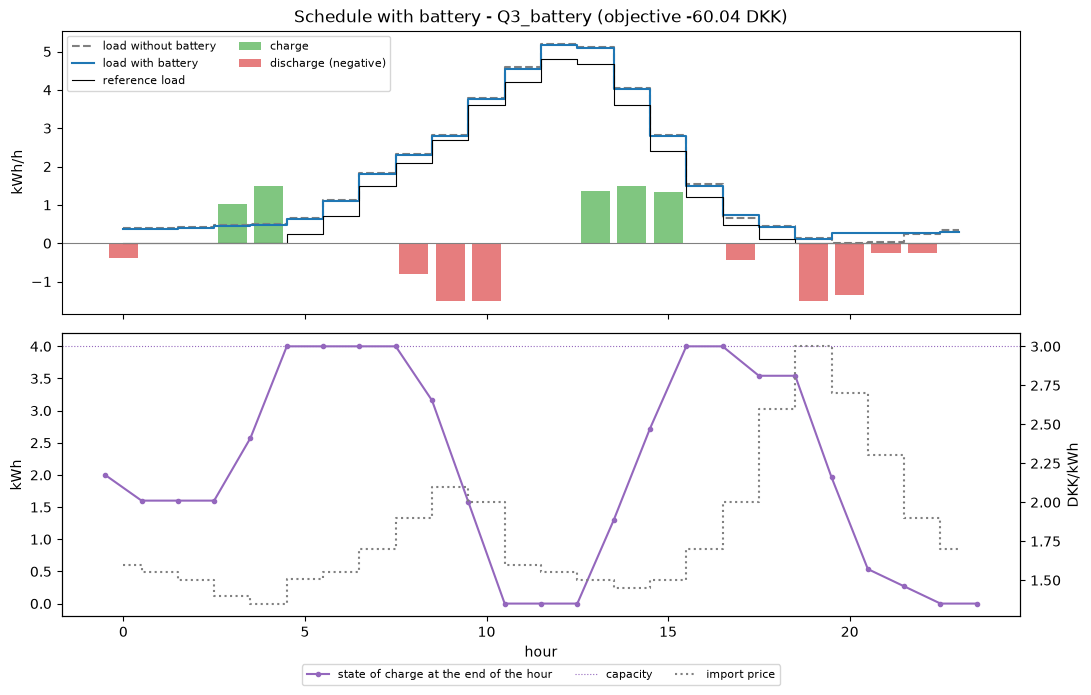

In [29]:
value = res_bat.objective - res_nobat.objective
print(f"objective with battery {res_bat.objective:.4f}, without {res_nobat.objective:.4f} -> value of the battery {value:.4f} DKK/day")
print(f"final state of charge {hr['soc'].iloc[-1]:.3f} kWh (initial {d.battery_initial_soc_kWh} kWh)")

plot_battery_schedule(res_bat, d, res_nobat)   # same figure as main.py (report/figures/Q3/q3g_battery_schedule.png)
plt.show()

## 9. `main.py` from the notebook (as from the terminal)

In [30]:
for question in ["Q1_caseA", "Q3", "Q3_battery"]:
    proc = subprocess.run([sys.executable, str(ROOT_DIR / "main.py"), "--question", question],
                          cwd=ROOT_DIR, capture_output=True, text=True)
    line = next((l for l in proc.stdout.splitlines() if l.startswith("status")), proc.stderr[-300:])
    print(f"{question:11s} {line}")
    assert proc.returncode == 0, proc.stderr

Q1_caseA    status: OPTIMAL | objective: 2.61 DKK (utility 51.39 - cost 48.79)
Q3          status: OPTIMAL | objective: -63.31 DKK
Q3_battery  status: OPTIMAL | objective: -60.04 DKK
